In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 05. Scalar-vector-tensor decomposition

Algebraic identities are proven for a fully generic symmetric $h_{ij}(\mathbf k)$; the numerical decomposition on a periodic box is then
tested for reconstruction error, transversality, resolution dependence, the $\mathbf k=0$ mode and small-$k$ error amplification.

In [2]:
from desitter_perturbations.symbolic import tensor_decomposition as td
res = td.verify_svt_identities()
for k, v in td.all_zero(res).items(): print(f"{k:24s} {v}")

P_idempotent             True
P_transverse             True
gamma_transverse         True
gamma_traceless          True
gamma_symmetric          True
F_transverse             True
reconstruction           True
Lambda_idempotent        True
Lambda_kills_scalar      True
Lambda_kills_vector      True


In [3]:
from desitter_perturbations.perturbations import svt_numeric as sv
for N in (8, 12, 16, 24):
    print(N, "round-trip error", sv.reconstruction_error(sv.random_symmetric_field(N, seed=N)))
g = sv.tt_part_field(16, seed=4)
print("spectral div  :", np.abs(sv.spectral_divergence(g)).max())
print("2nd-order FD  :", np.abs(sv.finite_difference_divergence(g)).max(), "(discretisation matters)")

8 round-trip error 5.551115123125783e-17
12 round-trip error 2.7755575615628914e-17
16 round-trip error 6.938893903907228e-18


24 round-trip error 3.469446951953614e-18


spectral div  : 2.6020852139652106e-17
2nd-order FD  : 0.002542611560194207 (discretisation matters)


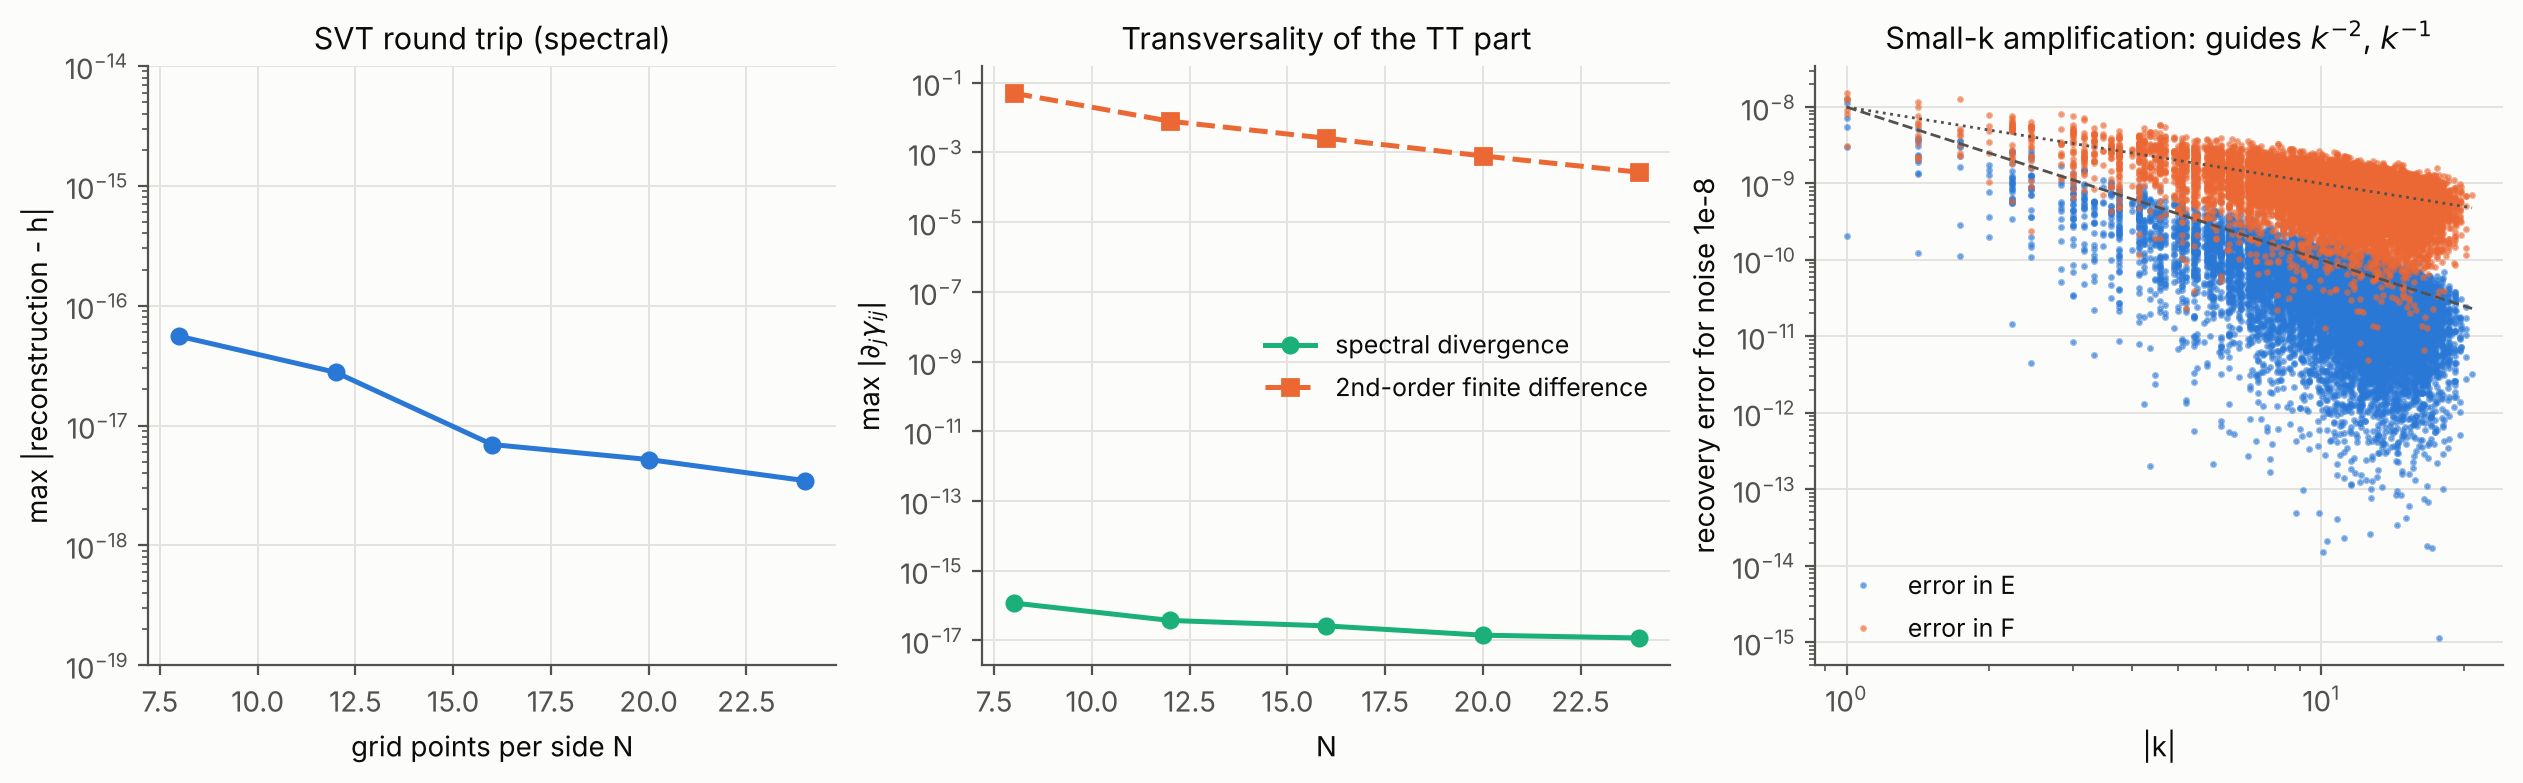

In [4]:
from desitter_perturbations.visualization import gauge_plots as gaup
show(gaup.plot_svt_diagnostics())

Boundary conditions: the SVT split is a Helmholtz-type decomposition; on a periodic box it is unique except for the homogeneous mode,
which is assigned to $\psi_0$ (trace) and a constant traceless $\gamma_0$. On non-periodic domains uniqueness depends on falloff conditions and none of these routines apply.